# Day 6 — Notebook 06b: Logistic Regression in Simple Words

**Logistic Regression answers a YES / NO question** — for example: *"Will this customer cancel?"*

| | Linear Regression | Logistic Regression |
|---|---|---|
| **Answers** | "**How much?**" | "**Yes or No?**" |
| **Output** | Any number (e.g. $250, 37.5 kg) | A probability from 0% to 100% |
| **Example** | Predict a house **price** | Predict if a customer **will cancel** |

### How it works in 4 steps
1. Give each clue a **weight** (importance score)
2. **Add** everything up into a score
3. **Squash** the score into a 0–100% probability (the S-curve)
4. **Decide**: ≥ 50% → "will cancel", < 50% → "will stay"

**Action:** Click **Run → Run All Cells**.

## Step 0: Our Tiny Data — 10 Past Customers

Two clues per customer:
- `support_tickets` — how many times they complained
- `logins_per_month` — how often they used the app

And the answer: `cancelled` (1 = cancelled, 0 = stayed)

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

data = pd.DataFrame({
    "support_tickets":  [4, 3, 5, 2, 4, 0, 1, 0, 1, 0],
    "logins_per_month": [2, 1, 3, 6, 4, 25, 20, 30, 18, 22],
    "cancelled":        [1, 1, 1, 1, 1, 0, 0, 0, 0, 0],
})
data

,support_tickets,logins_per_month,cancelled
0,4,2,1
1,3,1,1
2,5,3,1
3,2,6,1
4,4,4,1
5,0,25,0
6,1,20,0
7,0,30,0
8,1,18,0
9,0,22,0


## Step 1: Train the Model → It Learns a Weight for Each Clue

`model.fit()` looks at past customers and figures out how important each clue is.
- **Plus (+) weight** → pushes toward *"will cancel"*
- **Minus (−) weight** → pushes toward *"will stay"*

In [13]:
X = data[["support_tickets", "logins_per_month"]]
y = data["cancelled"]

model = LogisticRegression()
model.fit(X, y)          # <- training = learning the weights

weights = pd.DataFrame({"clue": X.columns, "weight": model.coef_[0].round(3)})
weights["pushes_toward"] = np.where(weights["weight"] > 0, "will CANCEL", "will STAY")
print("Starting value (intercept):", model.intercept_[0].round(3))
weights

Starting value (intercept): 6.918


,clue,weight,pushes_toward
0,support_tickets,0.078,will CANCEL
1,logins_per_month,-0.583,will STAY


## 🤔 Wait — What's the Difference Between `cancelled` (churned) and a "Weight"?

*(No ML background needed for this section!)*

These are **two completely different kinds of numbers**. People mix them up because 0 and 1 show up everywhere.

> 📝 In this notebook the answer column is called `cancelled`. In the main StreamPulse data it's called `churned`. **They mean exactly the same thing.**

### Everyday analogy: Predicting Rain 🌧️

Imagine you keep a diary for 10 days:

| Day | Dark clouds? | Sunny morning? | **Did it rain?** |
|---|---|---|---|
| Mon | Yes | No | **Yes (1)** |
| Tue | No | Yes | **No (0)** |
| … | … | … | … |

After a while, you learn some **rules of thumb**:
- *"Dark clouds → strong sign of rain"*  (big **+** weight)
- *"Sunny morning → sign of no rain"*  (**−** weight)

| | **"Did it rain?" column** | **Rules of thumb** |
|---|---|---|
| ML name | **Label / answer** (`churned`) | **Weight** |
| Where it comes from | **Written down** — what really happened | **Learned** by looking at many days |
| Values | **Only Yes (1) or No (0)** | **Any number** — how strong the sign is |
| One per… | **Each day** (each customer) | **Each clue** (each column) |

### Same idea for StreamPulse

| | **`churned` / `cancelled`** | **Weight** |
|---|---|---|
| **What is it?** | The **real answer**: did this customer leave? | **How important** a clue is |
| **Who creates it?** | The **business records** it (fact) | The **model learns** it (from the facts) |
| **Possible values** | **Only 0 or 1** | **Any number**, e.g. `+0.078`, `−0.583` |
| **0 / 1 meaning** | `0` = stayed, `1` = cancelled | Not 0/1! The **sign** shows direction |
| **How many?** | **One per customer** (10 customers → 10 answers) | **One per clue** (2 clues → 2 weights) |
| **Question it answers** | *"What happened to THIS customer?"* | *"How much does THIS clue matter?"* |

### How do they connect?
- The model **reads** the `churned` answers (0s and 1s) to **learn** the weights.
- A **+ weight** means: *"higher values of this clue are seen more with `churned = 1` (cancel)"*.
- A **− weight** means: *"higher values of this clue are seen more with `churned = 0` (stay)"*.

```text
   churned answers (0/1)   ──►   model studies them   ──►   weights (any number)
   "what happened"                                          "which clues matter, and how much"
   one per CUSTOMER                                         one per CLUE
```

Let's see both side by side 👇

In [ ]:
# 1) The ANSWERS: one per CUSTOMER, only 0 or 1 (facts we recorded)
answers = data[["support_tickets", "logins_per_month", "cancelled"]].copy()
answers["cancelled_means"] = answers["cancelled"].map({0: "stayed", 1: "CANCELLED"})
print("1) ANSWERS (cancelled / churned) - one row per CUSTOMER, only 0 or 1:")
display(answers)

# 2) The WEIGHTS: one per CLUE, any number (learned by the model)
print("\n2) WEIGHTS - one row per CLUE, any number (learned from the answers above):")
weights_explained = pd.DataFrame({
    "clue": X.columns,
    "weight": model.coef_[0].round(3),
})
weights_explained["in_plain_words"] = [
    "each extra complaint -> slightly MORE likely to cancel (pushes toward 1)",
    "each extra login     -> much LESS likely to cancel (pushes toward 0)",
]
display(weights_explained)

### Notice
- **Table 1 (answers)** has **10 rows** (one per customer) and only **0s and 1s**.
- **Table 2 (weights)** has **2 rows** (one per clue) and **decimal numbers with + or −**.
- The weights were **learned from** Table 1: customers who cancelled (`1`) had **few logins**, so logins got a **minus** weight (more logins → toward `0` = stay).

### Quick check ✅
| Number you see | What is it? |
|---|---|
| `cancelled = 1` | **Answer** — this customer left |
| `cancelled = 0` | **Answer** — this customer stayed |
| `weight = +0.078` | **Importance** — complaints push a little toward cancel |
| `weight = −0.583` | **Importance** — logins push strongly toward stay |

> 🧠 **One line:** `churned` = **what happened** (0 or 1, one per customer). Weight = **how much a clue matters** (any number, one per clue).

## Step 2: Add Everything Up into a Score

```text
score = (weight1 × support_tickets) + (weight2 × logins_per_month) + starting value
```

Let's calculate it **by hand** for one new customer: 4 tickets, 3 logins.

In [3]:
tickets, logins = 4, 3
w_tickets, w_logins = model.coef_[0]
start = model.intercept_[0]

score = w_tickets * tickets + w_logins * logins + start
print(f"score = ({w_tickets:.3f} × {tickets}) + ({w_logins:.3f} × {logins}) + ({start:.3f})")
print(f"score = {score:.3f}")

score = (0.078 × 4) + (-0.583 × 3) + (6.918)
score = 5.482


## Step 3: Squash the Score into a Probability (the S-Curve)

The **sigmoid** function turns ANY score into a number between 0 and 1 (0% – 100%):

```text
probability = 1 / (1 + e^(-score))
```

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

probability = sigmoid(score)
print(f"Score {score:.3f}  ->  probability of cancelling = {probability:.1%}")

Score 5.482  ->  probability of cancelling = 99.6%


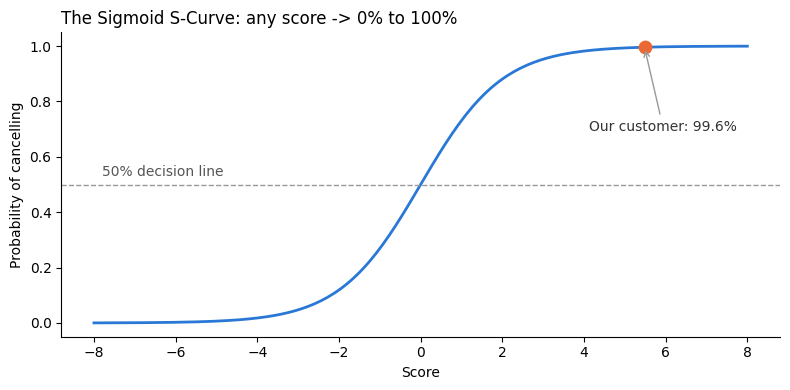

In [5]:
# Draw the S-curve and mark our customer on it
z = np.linspace(-8, 8, 200)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(z, sigmoid(z), color="#2a78d6", linewidth=2)
ax.axhline(0.5, color="#999999", linestyle="--", linewidth=1)
ax.text(-7.8, 0.53, "50% decision line", color="#555555")

shown = np.clip(score, -8, 8)
ax.scatter([shown], [probability], color="#eb6834", s=80, zorder=3)
ax.annotate(f"Our customer: {probability:.1%}", (shown, probability),
            xytext=(-40, -60), textcoords="offset points", color="#333333",
            arrowprops=dict(arrowstyle="->", color="#999999"))

ax.set_xlabel("Score")
ax.set_ylabel("Probability of cancelling")
ax.set_title("The Sigmoid S-Curve: any score -> 0% to 100%", loc="left")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

| Score | Probability | Meaning |
|---|---|---|
| Very negative (e.g. −4) | ~2% | will almost surely **stay** |
| 0 | 50% | could go either way |
| Very positive (e.g. +4) | ~98% | will almost surely **cancel** |

## Step 4: Make the Decision

```text
probability ≥ 50%  →  predict "WILL CANCEL" (1)
probability < 50%  →  predict "WILL STAY"   (0)
```

sklearn does Steps 2 + 3 + 4 for us with `predict_proba()` and `predict()`. Let's check it matches our hand calculation!

In [6]:
new_customer = pd.DataFrame({"support_tickets": [tickets], "logins_per_month": [logins]})

print("Our hand-calculated probability :", f"{probability:.1%}")
print("sklearn predict_proba (cancel)  :", f"{model.predict_proba(new_customer)[0, 1]:.1%}")
print("sklearn predict                 :", model.predict(new_customer)[0], "(1 = will cancel)")

Our hand-calculated probability : 99.6%
sklearn predict_proba (cancel)  : 99.6%
sklearn predict                 : 1 (1 = will cancel)


## Full Example: Two Very Different Customers

In [7]:
customers = pd.DataFrame({
    "support_tickets":  [4, 0],
    "logins_per_month": [2, 25],
}, index=["Customer A", "Customer B"])

customers["cancel_probability"] = (model.predict_proba(customers)[:, 1] * 100).round(1).astype(str) + "%"
customers["prediction"] = np.where(model.predict(customers[["support_tickets", "logins_per_month"]]) == 1,
                                   "🔴 Will cancel", "🟢 Will stay")
customers

,support_tickets,logins_per_month,cancel_probability,prediction
Customer A,4,2,99.8%,🔴 Will cancel
Customer B,0,25,0.0%,🟢 Will stay


## Why People Like Logistic Regression 👍
- **Simple & fast** — trains in a blink.
- **Easy to explain** — point at the weights: *"complaints raise the risk, logins lower it."*
- **Great first model** — always try it before fancier models. On StreamPulse it actually beat the complex ones!

## Remember in One Line 🧠
> **Logistic Regression = give each clue a weight → add them up → squash into a 0–100% chance → decide Yes or No.**